# Práctica I · Aprendizaje Estadístico (2026/2027)

## Análisis de salud cardiometabólica con NHANES

#### Mercedes López Caballero y María García Miñarro

**Dataset:** `data/nhanes_cardiometabolic_clean.csv` — *National Health and Nutrition Examination Survey* (CDC, EE. UU.).

**Estructura del trabajo:** 1) selección del conjunto de datos, 2) exploración, 3) regresión lineal, 4) Ridge y Lasso, 5) PCA, 6) regresión logística, 7) una única base de datos y 8) conclusiones.

Con una sola base de datos (unos 10.700 adultos de la encuesta NHANES de EE. UU.) contestamos dos preguntas: **predecir un número** (¿cuánto medirá la presión arterial? → regresión) y **predecir un sí/no** (¿tiene hipertensión? → clasificación). Para ello entrenamos los modelos con una parte de los datos y los evaluamos con otra que no han visto.

## 1. Selección del conjunto de datos

Hemos elegido **NHANES** (*National Health and Nutrition Examination Survey*), un estudio del CDC de EE. UU. que recoge, mediante cuestionarios, exploración física y análisis de laboratorio, el estado de salud y los hábitos de vida de la población estadounidense. Los datos son públicos y se descargan de la [web oficial de NHANES](https://wwwn.cdc.gov/nchs/nhanes/).

Usamos un dataset consolidado (`nhanes_cardiometabolic_clean.csv`, generado con `get_data.py`) con **10.739 adultos (≥ 20 años)** y **73 columnas**, centrado en la salud cardiometabólica (presión arterial, IMC, colesterol, glucosa y otros biomarcadores sanguíneos).

Lo elegimos por tres motivos:

- **Permite regresión y clasificación:** predecir la presión sistólica (`pas`, numérica) o el diagnóstico de hipertensión (`hipertension`, binario).
- **Variables correlacionadas entre sí**, lo que justifica usar Ridge, Lasso y PCA.
- **Variables de distinto tipo** (cuantitativas y cualitativas).

Así podemos aplicar todas las técnicas del enunciado con una única base de datos.

##2. Exploración de los datos



Antes de construir modelos, exploramos los datos: estructura, tipo de variables, distribuciones, relaciones y valores ausentes o anomalías relevantes para el análisis posterior.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import skew

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve)

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 6)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/nhanes_cardiometabolic_clean.csv")

# Traducción de nombres de variables y categorías al español
df = df.rename(columns={
    "seqn": "id_sujeto", "cycle": "ciclo", "psu": "conglomerado", "strata": "estrato",
    "wt_mec": "peso_examen", "wt_fasting": "peso_ayunas",
    "fasting_subsample": "submuestra_ayunas",
    "age": "edad", "sex": "sexo", "race_eth": "etnia", "education": "educacion",
    "income_poverty_ratio": "ingresos_pobreza",
    "sbp": "pas", "dbp": "pad", "sbp1": "pas1", "dbp1": "pad1",
    "pulse": "pulso", "weight": "peso", "height": "altura", "bmi": "imc", "waist": "cintura",
    "smoking": "tabaco", "diabetes_dx": "diabetes", "hypertension_dx": "hipertension",
    "bp_meds": "medicacion_pa", "chol_meds": "medicacion_colesterol",
    "total_chol": "colesterol_total", "triglycerides": "trigliceridos",
    "glucose_fasting": "glucosa_ayunas", "insulin": "insulina",
    "hs_crp": "proteina_c_reactiva",
    "bilirubin": "bilirrubina", "albumin": "albumina", "total_protein": "proteinas_totales",
    "globulin": "globulina", "creatinine": "creatinina", "uric_acid": "acido_urico",
    "sodium": "sodio", "potassium": "potasio", "chloride": "cloro",
    "bicarbonate": "bicarbonato", "calcium": "calcio", "phosphorus": "fosforo",
    "iron": "hierro", "osmolality": "osmolaridad",
    "glucose_serum": "glucosa_suero", "chol_serum": "colesterol_suero",
    "trig_serum": "trigliceridos_suero",
    "wbc": "leucocitos", "lymph_pct": "linfocitos_pct", "mono_pct": "monocitos_pct",
    "neut_pct": "neutrofilos_pct", "eos_pct": "eosinofilos_pct", "baso_pct": "basofilos_pct",
    "rbc": "eritrocitos", "hemoglobin": "hemoglobina", "hematocrit": "hematocrito",
    "platelets": "plaquetas",
})

# Categorías en español
df["sexo"] = df["sexo"].replace({"male": "hombre", "female": "mujer"})
df["tabaco"] = df["tabaco"].replace({"current": "fumador", "former": "exfumador", "never": "nunca"})
df["hipertension"] = df["hipertension"].replace({"yes": "si", "no": "no"})
df["diabetes"] = df["diabetes"].replace({"yes": "si", "no": "no", "borderline": "limite"})
df["medicacion_pa"] = df["medicacion_pa"].replace({"yes": "si", "no": "no"})
df["medicacion_colesterol"] = df["medicacion_colesterol"].replace({"yes": "si", "no": "no"})
df["etnia"] = df["etnia"].replace({
    "nh_white": "blanco_no_hispano", "nh_black": "negro_no_hispano",
    "mexican_american": "mexicano_americano", "other_hispanic": "otro_hispano",
    "other_multiracial": "otro_multirracial", "nh_asian": "asiatico_no_hispano",
})
df["educacion"] = df["educacion"].replace({
    "college_grad": "universitaria", "some_college": "universitaria_incompleta",
    "high_school": "secundaria", "9_11th": "secundaria_incompleta", "less_9th": "primaria",
})

print("Número de observaciones:", df.shape[0])
print("Número de variables:", df.shape[1])
df.head()


Número de observaciones: 10739
Número de variables: 73


,id_sujeto,ciclo,conglomerado,estrato,peso_examen,peso_ayunas,submuestra_ayunas,edad,sexo,etnia,...,basofilos_pct,eritrocitos,hemoglobina,hematocrito,mcv,mch,mchc,rdw,plaquetas,mpv
0,83732,2015-2016,1,125,67814.753703,NaN,False,62,hombre,blanco_no_hispano,...,0.5,4.93,15.2,44.7,90.8,30.8,34.0,13.9,181.0,8.3
1,83733,2015-2016,1,125,12641.212964,27361.171665,True,53,hombre,blanco_no_hispano,...,1.8,4.89,17.5,49.7,101.8,35.8,35.1,13.4,170.0,9.6
2,83734,2015-2016,1,131,6287.919409,12735.546850,True,78,hombre,blanco_no_hispano,...,0.9,4.18,12.4,37.9,90.8,29.6,32.6,14.7,223.0,9.0
3,83735,2015-2016,1,131,51039.317254,NaN,False,56,mujer,blanco_no_hispano,...,0.9,4.54,12.8,40.1,88.3,28.2,31.9,13.1,280.0,9.1
4,83736,2015-2016,2,126,9117.368109,19089.755435,True,42,mujer,negro_no_hispano,...,0.2,4.16,12.1,36.5,87.8,29.1,33.2,12.3,275.0,7.7


### Estructura del conjunto de datos

El dataset tiene **10.739 filas y 73 columnas**: cada fila es un participante y cada columna una medición o característica (edad, sexo, presión arterial, análisis de sangre…).

Junto a las variables de salud hay columnas del diseño del estudio (`id_sujeto`, `ciclo`, `peso_examen`, `peso_ayunas`, `submuestra_ayunas`). No todas se usarán en los modelos: algunas solo identifican al participante o describen el muestreo.

### Descripción de las variables

Las variables se agrupan en los siguientes bloques:

| Grupo | Columnas |
|---|---|
| Diseño muestral | `id_sujeto`, `ciclo`, `conglomerado`, `estrato`, `peso_examen`, `peso_ayunas`, `submuestra_ayunas` |
| Demografía | `edad`, `sexo`, `etnia`, `educacion`, `ingresos_pobreza` |
| Exploración física | `pas`, `pad` (medias), `pas1`, `pad1`, `pulso`, `peso`, `altura`, `imc`, `cintura` |
| Cuestionarios | `tabaco`, `diabetes`, `hipertension`, `medicacion_pa`, `medicacion_colesterol` |
| Lípidos y glucosa | `colesterol_total`, `hdl`, `ldl`, `trigliceridos`, `glucosa_ayunas`, `insulina`, `hba1c` |
| Inflamación | `proteina_c_reactiva` |
| Hígado | `alt`, `ast`, `alp`, `ggt`, `ldh`, `bilirrubina`, `albumina`, `proteinas_totales`, `globulina` |
| Riñón | `creatinina`, `bun`, `acido_urico` |
| Electrolitos/minerales | `sodio`, `potasio`, `cloro`, `bicarbonato`, `calcio`, `fosforo`, `hierro`, `osmolaridad` |
| Bioquímica sin ayuno | `glucosa_suero`, `colesterol_suero`, `trigliceridos_suero`, `cpk` |
| Hemograma | `leucocitos`, `linfocitos_pct`, `monocitos_pct`, `neutrofilos_pct`, `eosinofilos_pct`, `basofilos_pct`, `eritrocitos`, `hemoglobina`, `hematocrito`, `mcv`, `mch`, `mchc`, `rdw`, `plaquetas`, `mpv` |

Las variables de la **submuestra en ayunas** (`ldl`, `trigliceridos`, `glucosa_ayunas`, `insulina`) solo se midieron a los participantes de la sesión de mañana que acudieron sin comer (unas 4.500 personas); para el resto son `NaN` por diseño, no por pérdida de datos (la glucosa, los triglicéridos y la insulina suben tras comer, y el LDL se calcula a partir de los triglicéridos). Por contraste, la **bioquímica sin ayuno** (`glucosa_suero`, `colesterol_suero`, `trigliceridos_suero`) se midió a todos los participantes, a cualquier hora: hay más casos, pero más ruidosos.

### Variables cuantitativas y cualitativas

Distinguimos entre variables **cuantitativas** (cantidades medibles: edad, peso, presión) y **cualitativas** (categorías: sexo, tabaco, diagnósticos). Una variable no es cuantitativa por estar almacenada como número: `id_sujeto`, `conglomerado` y `estrato` describen el diseño del estudio, y `submuestra_ayunas` es cualitativa aunque pandas la guarde como booleana.

In [3]:
#Variables relacionadas con el diseño del estudio
design_vars = ["id_sujeto", "conglomerado", "estrato", "peso_examen", "peso_ayunas"]

#Variables cualitativas (incluimos las booleanas)
categorical = df.select_dtypes(
    include=["object", "string", "bool"]
).columns.tolist()

#Variables cuantitativas, excluyendo identificadores y diseño muestral
quantitative = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in design_vars
]

print("Variables de diseño:", len(design_vars), design_vars)
print()
print("Variables cualitativas:", len(categorical), categorical)
print()
print("Variables cuantitativas:", len(quantitative))
print("Primeras 20:", quantitative[:20])

Variables de diseño: 5 ['id_sujeto', 'conglomerado', 'estrato', 'peso_examen', 'peso_ayunas']

Variables cualitativas: 10 ['ciclo', 'submuestra_ayunas', 'sexo', 'etnia', 'educacion', 'tabaco', 'diabetes', 'hipertension', 'medicacion_pa', 'medicacion_colesterol']

Variables cuantitativas: 58
Primeras 20: ['edad', 'ingresos_pobreza', 'pas', 'pas1', 'pad', 'pad1', 'pulso', 'peso', 'altura', 'imc', 'cintura', 'colesterol_total', 'hdl', 'ldl', 'trigliceridos', 'glucosa_ayunas', 'insulina', 'hba1c', 'proteina_c_reactiva', 'albumina']


La mayoría de las variables son cuantitativas, lo que conviene para regresión, Ridge, Lasso y PCA; las cualitativas nos permiten estudiar hábitos y diagnósticos. Separamos además las variables de diseño para no confundirlas con las mediciones.

### Resumen estadístico

Mostramos estadísticos de ocho variables relevantes (edad, medidas corporales, presión arterial e indicadores sanguíneos) con `describe()`.

In [4]:
#Resumen numérico de algunas variables relevantes
df[["edad", "imc", "pas", "pad", "colesterol_total", "hdl", "hba1c", "proteina_c_reactiva"]].describe().round(2)

,edad,imc,pas,pad,colesterol_total,hdl,hba1c,proteina_c_reactiva
count,10739.00,10581.00,10314.00,10287.00,10094.00,10094.00,10219.00,10042.00
mean,50.42,29.69,126.28,71.49,189.25,53.75,5.86,4.27
std,17.71,7.24,19.26,11.87,41.51,16.73,1.14,8.25
min,20.00,14.20,72.70,8.00,76.00,6.00,3.80,0.08
25%,35.00,24.70,112.70,64.00,161.00,42.00,5.30,0.83
50%,51.00,28.50,123.30,71.30,186.00,51.00,5.60,2.00
75%,65.00,33.40,136.00,78.70,214.00,63.00,6.00,4.60
max,80.00,86.20,238.00,138.70,545.00,226.00,17.00,188.50


De esta tabla destacamos:

- **Edad:** media de unos 50 años, de 20 a 80. NHANES agrupa en 80 a todos los de 80 o más años.
- **IMC (`imc`):** media 29,69 y mediana 28,50; la cola derecha (valores altos) eleva la media.
- **Presión (`pas` y `pad`):** medias 126,28 y 71,49 mmHg, con máximos alejados (la sistólica llega a 238).
- **Colesterol total (`colesterol_total`):** media 189,25 mg/dL, máximo 545.
- **Proteína C reactiva (`proteina_c_reactiva`):** media 4,27 pero mediana 2 y máximo 188,5; distribución muy desplazada a la derecha.

Además, la fila `count` revela valores ausentes (p. ej., hay edad de los 10.739 pero presión sistólica solo de 10.314), que analizaremos después.

### Visualizaciones relevantes

Representamos la distribución de algunas variables, la presión arterial por grupos y las correlaciones entre indicadores.

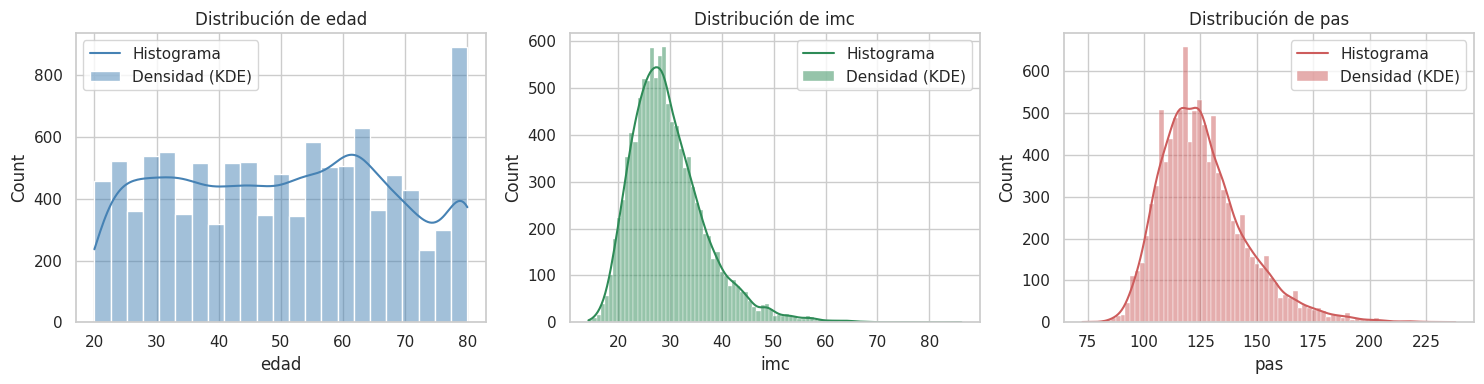

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var, color in zip(axes, ["edad", "imc", "pas"], ["steelblue", "seagreen", "indianred"]):
    sns.histplot(data=df, x=var, kde=True, color=color, ax=ax)
    ax.set_title(f"Distribución de {var}")
    ax.legend(["Histograma", "Densidad (KDE)"])
plt.tight_layout()
plt.show()

- **Edad (`edad`):** repartida entre 20 y 80 años, con un pico en 80 porque NHANES agrupa ahí a los de 80 o más.
- **IMC (`imc`):** concentrado en 25–30, con cola a la derecha (media > mediana).
- **Presión sistólica (`pas`):** forma de campana en torno a 120–130 mmHg, con cola hacia valores altos.

En general, algunas variables son bastante simétricas y otras presentan colas a la derecha que habrá que tener en cuenta al modelar.

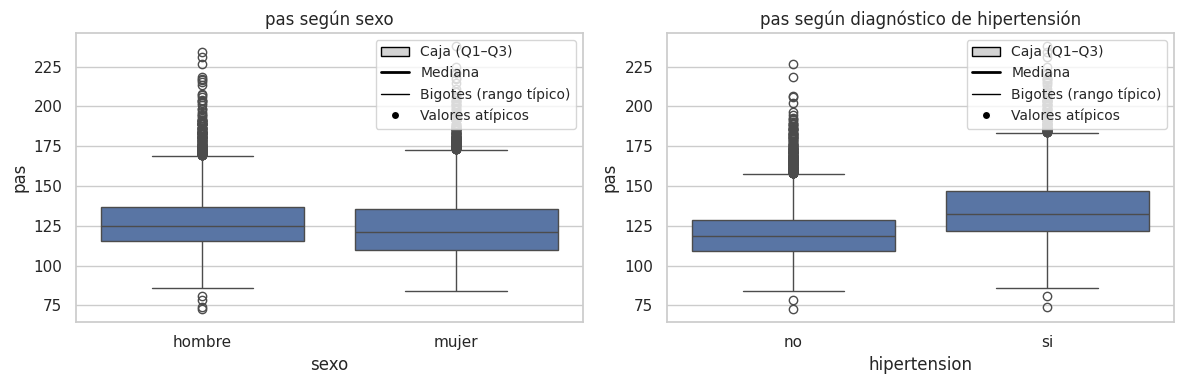

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="sexo", y="pas", ax=axes[0])
axes[0].set_title("pas según sexo")
sns.boxplot(data=df, x="hipertension", y="pas", ax=axes[1])
axes[1].set_title("pas según diagnóstico de hipertensión")

#Leyenda: qué representa cada parte del diagrama de caja
box_legend = [
    Patch(facecolor="lightgrey", edgecolor="black", label="Caja (Q1–Q3)"),
    Line2D([0], [0], color="black", lw=2, label="Mediana"),
    Line2D([0], [0], color="black", lw=1, label="Bigotes (rango típico)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
           markersize=6, label="Valores atípicos"),
]
axes[0].legend(handles=box_legend, fontsize="small", loc="upper right")
axes[1].legend(handles=box_legend, fontsize="small", loc="upper right")
plt.tight_layout()
plt.show()

- **Por sexo:** los hombres tienen una mediana algo mayor (≈ 124,7 frente a 121,3 mmHg), aunque las distribuciones se solapan bastante.
- **Por diagnóstico de hipertensión:** diferencia clara (mediana ≈ 132,7 frente a 118,7 mmHg), como era de esperar, aunque también se solapan: una medición alta no implica diagnóstico y una persona diagnosticada puede tener valores bajos si sigue tratamiento.

La presión arterial presenta diferencias entre grupos (sobre todo por el diagnóstico), sin que ello implique causalidad.

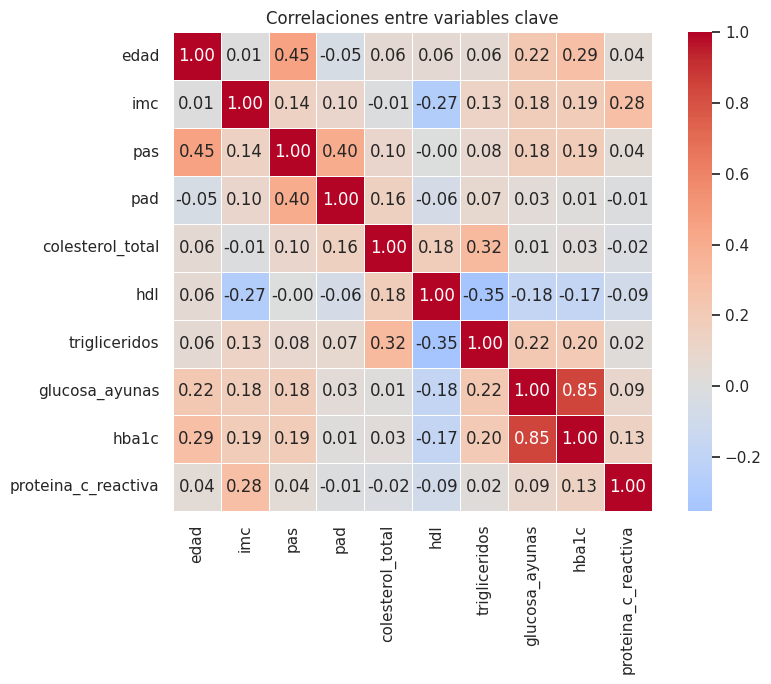

In [7]:
#Correlación entre biomarcadores clave (pairwise: ignora NA)
key = ["edad", "imc", "pas", "pad", "colesterol_total", "hdl", "trigliceridos",
       "glucosa_ayunas", "hba1c", "proteina_c_reactiva"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[key].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlaciones entre variables clave")
plt.tight_layout()
plt.show()

Destacan algunas relaciones:

- **`glucosa_ayunas` y `hba1c`:** correlación positiva fuerte (r ≈ 0,85); ambas reflejan los niveles de glucosa.
- **`edad` y `pas`:** correlación positiva (r ≈ 0,45); a más edad, más presión sistólica.
- **`pas` y `pad`:** positivas (r ≈ 0,40), aunque no perfectas.
- **`hdl` y `trigliceridos`:** correlación negativa (r ≈ −0,35).

Hay variables muy relacionadas entre sí, lo que justifica el uso posterior de **Ridge, Lasso y PCA**. Como siempre, correlación no implica causalidad.

###Valores ausentes

In [8]:
missing = df.isna().mean().sort_values(ascending=False)
print("Variables con mayor proporción de ausentes (%):")
print((missing.head(15) * 100).round(1).to_string())

print()
print("Observaciones sin ningún valor ausente:", df.dropna().shape[0], "de", df.shape[0])

Variables con mayor proporción de ausentes (%):
medicacion_colesterol    71.9
ldl                      57.2
trigliceridos            56.7
insulina                 55.3
glucosa_ayunas           54.5
peso_ayunas              52.1
ingresos_pobreza         11.8
pad1                      9.2
pas1                      8.6
ldh                       7.3
proteina_c_reactiva       6.5
ast                       6.4
cintura                   6.4
cpk                       6.4
globulina                 6.3

Observaciones sin ningún valor ausente: 989 de 10739


Casos relevantes de valores ausentes:

- **Submuestra en ayunas:** `ldl`, `trigliceridos`, `glucosa_ayunas` e `insulina` tienen entre un 54 % y un 57 % de ausentes por diseño del estudio (solo se midieron en la sesión de mañana).
- **`medicacion_colesterol`:** 71,9 % de ausentes (muy poca información).
- **`ingresos_pobreza`:** 11,8 %; **`pas1`/`pad1`:** ≈ 9 %.

Si exigimos las 73 columnas completas solo quedan **989 de 10.739** observaciones (> 90 % de pérdida). Por eso aplicamos `dropna()` únicamente sobre las columnas de cada modelo y excluimos la submuestra en ayunas en algunos análisis. Limitación: trabajar con casos completos cambia la muestra según el modelo y no imputamos los ausentes.

###Anomalías y aspectos relevantes

In [9]:
#1) globulina es una combinación lineal exacta de proteinas_totales y albumina
g = df[["globulina", "proteinas_totales", "albumina"]].dropna()
print("globulina == proteinas_totales - albumina :",
      np.allclose(g["globulina"], g["proteinas_totales"] - g["albumina"]))

#2) Asimetría de los biomarcadores
num_vars = ["edad", "imc", "pas", "colesterol_total", "hdl", "trigliceridos", "insulina",
            "proteina_c_reactiva", "ggt", "alt", "cpk", "glucosa_ayunas"]
sk = pd.Series({c: skew(df[c].dropna()) for c in num_vars}).sort_values(ascending=False)
print()
print("Asimetría (skewness) de variables seleccionadas:")
print(sk.round(2).to_string())

globulina == proteinas_totales - albumina : True

Asimetría (skewness) de variables seleccionadas:
cpk                    20.58
ggt                    12.66
trigliceridos           9.09
insulina                8.51
proteina_c_reactiva     8.22
alt                     4.58
glucosa_ayunas          3.87
hdl                     1.22
imc                     1.20
pas                     1.03
colesterol_total        0.73
edad                    0.02


**1. Información repetida.** `globulina = proteinas_totales − albumina` (comprobado en los datos). Incluir las tres crearía dependencia lineal exacta, así que excluimos `globulina`.

**2. Distribuciones muy asimétricas.** `cpk` (20,58), `ggt` (12,66), `trigliceridos` (9,09), `insulina` (8,51) y `proteina_c_reactiva` (8,22) tienen colas largas a la derecha; les aplicaremos `log(1+x)`.

**3. Multicolinealidad.** `colesterol_total`–`colesterol_suero` (0,99), `hemoglobina`–`hematocrito` (0,97), `sodio`–`osmolaridad` (0,81) y `ast`–`alt` (0,73) están muy correlacionadas, lo que complica la interpretación de los coeficientes. Justifica usar Ridge, Lasso y PCA.

**4. Medicación.** Quienes toman antihipertensivos (`medicacion_pa`) o estatinas (`medicacion_colesterol`) tienen la presión o el colesterol tratados, lo que puede atenuar las asociaciones observadas.

## 3. Regresión lineal

Queremos **predecir una variable numérica** (la presión arterial) a partir de otras. Analizamos primero las relaciones y después ajustamos un modelo simple (un predictor) y otro múltiple (varios), para ver si añadir variables mejora las predicciones.

### 3.1. Variable respuesta y relación con los predictores

La **variable respuesta** es la presión arterial sistólica (`pas`, en mmHg). Antes de modelar, representamos su relación con tres predictores: `edad`, `imc` y `colesterol_total`.

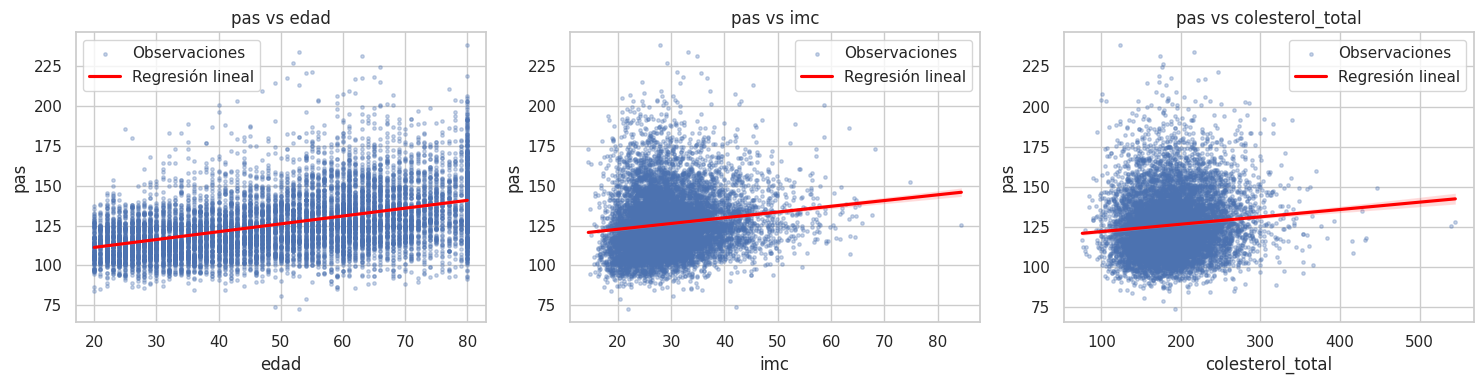

In [10]:
resp = "pas"
#Relación gráfica de pas con algunos predictores
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ["edad", "imc", "colesterol_total"]):
    d = df[[resp, var]].dropna()
    sns.regplot(data=d, x=var, y=resp,
                scatter_kws={"s": 6, "alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{resp} vs {var}")
    ax.collections[0].set_label("Observaciones")
    ax.lines[0].set_label("Regresión lineal")
    ax.legend()
plt.tight_layout()
plt.show()

- **`pas` vs `edad`:** relación positiva clara (la recta sube), aunque con dispersión.
- **`pas` vs `imc`:** relación positiva pero poco marcada.
- **`pas` vs `colesterol_total`:** recta casi horizontal; sin relación lineal clara por separado.

La **edad** es el predictor más relacionado con `pas`, así que empezamos por un modelo simple con ella.

### 3.2. Regresión lineal simple (`pas ~ edad`)

Ajustamos por mínimos cuadrados ordinarios (OLS) con la edad como único predictor, eliminando los casos sin información en estas dos variables (**10.314 participantes**).

In [11]:
d_simple = df[[resp, "edad"]].dropna()
X_s = sm.add_constant(d_simple["edad"])
model_simple = sm.OLS(d_simple[resp], X_s).fit()
print(model_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                    pas   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     2642.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:52:14   Log-Likelihood:                -43969.
No. Observations:               10314   AIC:                         8.794e+04
Df Residuals:                   10312   BIC:                         8.796e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        101.4229      0.512    197.973      0.0

**Interpretación del modelo simple**

La ecuación ajustada es:

$$\widehat{\text{pas}} = 101{,}42 + 0{,}492 \cdot \text{edad}$$

- **Intercepto (101,42):** presión estimada para una persona de 0 años; sin interpretación práctica (solo adultos).
- **Pendiente (0,492):** por cada año más de edad, la presión sistólica aumenta en media ≈ 0,49 mmHg (unos 4,9 mmHg por década). Es significativa (p < 0,001).
- **R² = 0,204:** la edad explica el 20,4 % de la variabilidad de `pas`.

Ejemplos: 20 años → ≈ 111,3 mmHg; 80 años → ≈ 140,8 mmHg. Son estimaciones medias del modelo, no valores de personas concretas.

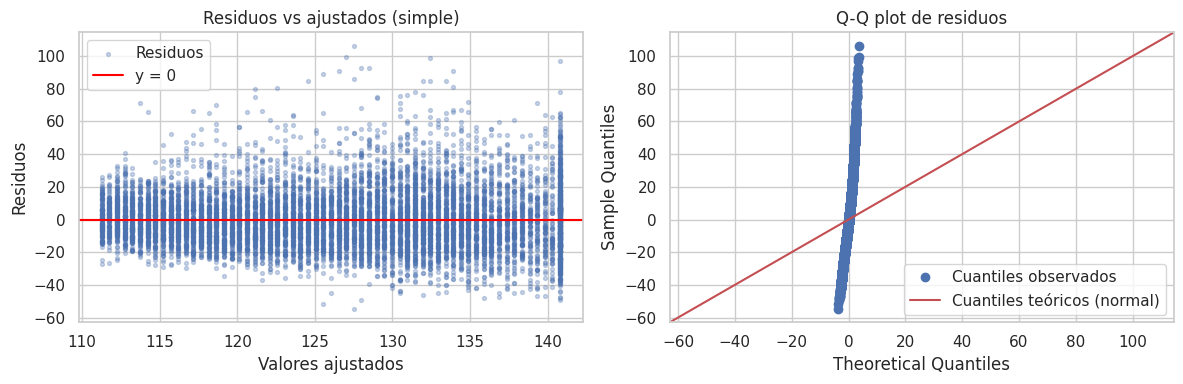

In [12]:
#Residuos del modelo simple
fitted = model_simple.fittedvalues
resid = model_simple.resid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, resid, s=8, alpha=0.3, label="Residuos")
axes[0].axhline(0, color="red", label="y = 0")
axes[0].set_xlabel("Valores ajustados"); axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos vs ajustados (simple)")
axes[0].legend()
sm.qqplot(resid, line="45", ax=axes[1])
axes[1].set_title("Q-Q plot de residuos")
axes[1].legend(["Cuantiles observados", "Cuantiles teóricos (normal)"])
plt.tight_layout()
plt.show()

Los **residuos** (diferencia entre el valor real y el predicho) permiten comprobar los supuestos del modelo:

- **Residuos vs ajustados (izquierda):** se reparten en una banda más o menos constante alrededor de 0, sin curvatura clara; una relación lineal es una primera aproximación razonable.
- **Q-Q plot (derecha):** los residuos se acercan a la diagonal, con desviaciones en los extremos (colas algo más pesadas que una normal).

En conjunto, el modelo capta la tendencia, pero predice con incertidumbre la presión individual.

### 3.3. Regresión lineal múltiple

Añadimos predictores a la edad: `imc`, `colesterol_total`, `hdl`, `sexo` y `tabaco`. Las cualitativas se convierten en binarias con `get_dummies()` (referencias: *mujer* y *fumador*). Tras eliminar los ausentes quedan **9.620 participantes**. La diferencia clave con el modelo simple es que cada coeficiente mide el efecto de una variable **manteniendo constantes las demás**.

In [13]:
cols = [resp, "edad", "imc", "colesterol_total", "hdl", "sexo", "tabaco"]
d_multi = df[cols].dropna()

#Convertimos las variables categóricas en columnas numéricas (0 y 1)
d_multi = pd.get_dummies(
    d_multi,
    columns=["sexo", "tabaco"],
    dtype=int,
)
# Categorías de referencia: "mujer" (sexo) y "fumador" (tabaco)
d_multi = d_multi.drop(columns=["sexo_mujer", "tabaco_fumador"])

y_m = d_multi[resp]
X_m = d_multi.drop(columns=resp)
X_m_const = sm.add_constant(X_m)

model_multi = sm.OLS(y_m, X_m_const).fit()
print(model_multi.summary())

                            OLS Regression Results                            
Dep. Variable:                    pas   R-squared:                       0.236
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     423.5
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:52:14   Log-Likelihood:                -40657.
No. Observations:                9620   AIC:                         8.133e+04
Df Residuals:                    9612   BIC:                         8.139e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               81.8482      1.433  

**Interpretación del modelo múltiple**

El modelo alcanza **R² = 0,236**. Coeficientes principales:

- **`edad` (+0,488):** ≈ 0,49 mmHg por año, casi igual que en el modelo simple.
- **`imc` (+0,394):** ≈ 0,39 mmHg por unidad de IMC.
- **`colesterol_total` (+0,034):** efecto pequeño por mg/dL (≈ 0,34 mmHg por cada 10 mg/dL).
- **`hdl` (+0,018):** no significativo (p = 0,113).
- **`sexo_hombre` (+3,09):** los hombres presentan ≈ 3,09 mmHg más que las mujeres, a igualdad del resto.
- **`tabaco`:** frente a los fumadores, los exfumadores −2,14 mmHg y los que nunca fumaron −0,85 mmHg (este último con p = 0,065).

Son **asociaciones**, no relaciones causales (p. ej., haber fumado no "baja" la presión).

**Comparación con el modelo simple:** el R² pasa de 0,204 a 0,236 (+3,2 puntos). El modelo múltiple mejora el ajuste, pero poco: quedan muchos factores sin recoger.

###3.4 Predicciones para nuevas observaciones

In [14]:
#Nueva observación: mujer, 55 años, IMC 28, colesterol total 200, HDL 55, no fumadora
nueva = pd.DataFrame([{"edad": 55, "imc": 28, "colesterol_total": 200, "hdl": 55,
                       "sexo_hombre": 0, "tabaco_exfumador": 0, "tabaco_nunca": 1}])[X_m.columns]
pred_nueva = model_multi.predict(sm.add_constant(nueva, has_constant="add"))[0]
print(f"Predicción de pas para la nueva observación: {pred_nueva:.1f} mmHg")

#Intervalos al 95 %: de confianza (para la media de personas con ese perfil)
#y de predicción (para una persona concreta, incluye la variabilidad individual)
pred_int = model_multi.get_prediction(sm.add_constant(nueva, has_constant="add")).summary_frame(alpha=0.05)
print(f"IC 95 % (media):      [{pred_int['mean_ci_lower'][0]:.1f}, {pred_int['mean_ci_upper'][0]:.1f}] mmHg")
print(f"IP 95 % (individuo):  [{pred_int['obs_ci_lower'][0]:.1f}, {pred_int['obs_ci_upper'][0]:.1f}] mmHg")

Predicción de pas para la nueva observación: 126.7 mmHg
IC 95 % (media):      [126.1, 127.2] mmHg
IP 95 % (individuo):  [94.2, 159.2] mmHg


Usamos el modelo múltiple para predecir una persona ficticia (mujer, 55 años, IMC 28, colesterol total 200, HDL 55, no fumadora): **pas estimada ≈ 126,7 mmHg**.

El **intervalo de confianza** (media del perfil) es estrecho porque con ≈ 9.600 observaciones la media se estima con precisión; el **intervalo de predicción** (una persona concreta) es mucho más ancho, pues añade la variabilidad individual que el modelo no explica (R² ≈ 0,24). Es decir, describe bien la tendencia media, pero predice con incertidumbre a un individuo.

In [15]:
#Evaluación predictiva simple vs múltiple (train/test)
# Enseñamos con el 80 % (entrenamiento) y comprobamos con el 20 % que el modelo no ha visto (test). Así medimos si generaliza a gente nueva y no
#   se ha aprendido los datos de memoria.
#   - MSE: error medio de las predicciones (cuanto más bajo, mejor).
#   - R²: proporción de la variación de pas que explica el modelo.

X_tr, X_te, y_tr, y_te = train_test_split(
    X_m_const, y_m, test_size=0.2, random_state=RANDOM_STATE)

ols_simple = sm.OLS(y_tr, X_tr[["const", "edad"]]).fit()
ols_multi = sm.OLS(y_tr, X_tr).fit()

for name, model, cols_use in [("Simple", ols_simple, ["const", "edad"]),
                              ("Múltiple", ols_multi, X_tr.columns)]:
    pred = model.predict(X_te[cols_use])
    print(f"{name:9s} -> MSE test = {mean_squared_error(y_te, pred):.1f} | "
          f"R² test = {r2_score(y_te, pred):.3f}")

Simple    -> MSE test = 297.3 | R² test = 0.217
Múltiple  -> MSE test = 289.0 | R² test = 0.239


**Comparación con datos de test**

Dividimos en entrenamiento (80 %) y test (20 %), con la misma partición para ambos modelos:

| Modelo | MSE test | R² test |
|---|---:|---:|
| Regresión simple | 297,3 | 0,217 |
| Regresión múltiple | 289,0 | 0,239 |

El modelo múltiple mejora ligeramente (R² de 0,217 a 0,239, +2,2 puntos), pero la ganancia es modesta: añadir IMC, colesterol, sexo y tabaco ayuda poco respecto a usar solo la edad.

## 4. Selección y regularización: Ridge y Lasso

Ahora usamos los 46 biomarcadores disponibles. Al estar muy correlacionados (**multicolinealidad**), los coeficientes de OLS pueden ser inestables. La regularización lo corrige:

- **Ridge (L2):** reduce los coeficientes hacia cero, pero no elimina variables.
- **Lasso (L1):** puede hacer que algunos coeficientes sean exactamente cero (selección de variables).

El parámetro **α** controla la intensidad de la penalización. Lo elegimos con **validación cruzada de 10 particiones** sobre el entrenamiento, sin tocar el test.

### Preparación de los datos

Seleccionamos **46 predictores numéricos**, excluyendo la submuestra en ayunas (`ldl`, `trigliceridos`, `glucosa_ayunas`, `insulina`) para no perder observaciones, y `globulina` (dependencia lineal exacta). Aplicamos `log(1+x)` a las variables asimétricas (`proteina_c_reactiva`, `ggt`, `alt`, `cpk`, `trigliceridos_suero`) y eliminamos los ausentes: **9.075 participantes y 46 predictores**.

Dividimos en entrenamiento (80 %, 7.260) y test (20 %, 1.815), y estandarizamos con `StandardScaler` dentro de un `Pipeline` para que la penalización sea comparable entre variables.

In [16]:
#Panel numérico "sin ayunas" (sin las 4 variables de la submuestra en ayunas ni globulina)
# Elegimos 46 medidas de sangre/cuerpo disponibles para casi todas las personas.
panel = [
    "edad", "imc", "cintura", "pulso",
    "colesterol_total", "hdl", "hba1c", "proteina_c_reactiva",
    "albumina", "proteinas_totales",
    "alt", "ast", "alp", "ggt", "ldh", "bilirrubina", "cpk",
    "bun", "creatinina", "acido_urico",
    "sodio", "potasio", "cloro", "bicarbonato",
    "calcio", "fosforo", "hierro", "osmolaridad",
    "glucosa_suero", "colesterol_suero", "trigliceridos_suero",
    "leucocitos", "eritrocitos", "hemoglobina", "hematocrito", "mcv", "mch", "mchc", "rdw",
    "plaquetas", "mpv",
    "linfocitos_pct", "monocitos_pct", "neutrofilos_pct", "eosinofilos_pct", "basofilos_pct",
]
skewed = ["proteina_c_reactiva", "ggt", "alt", "cpk", "trigliceridos_suero"]

data_pen = df[panel + ["pas"]].copy()
for c in skewed:
    data_pen[c] = np.log1p(data_pen[c])
data_pen = data_pen.dropna()

X_pen = data_pen[panel]
y_pen = data_pen["pas"]
print("Casos completos para Ridge/Lasso/PCA:", X_pen.shape)

Casos completos para Ridge/Lasso/PCA: (9075, 46)


In [17]:
# Separamos 80 % (entrenar) / 20 % (test). El test NO se toca hasta el final.
X_train, X_test, y_train, y_test = train_test_split(
    X_pen, y_pen, test_size=0.2, random_state=RANDOM_STATE)
print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)

# Validación cruzada: para elegir el mejor alpha, dividimos el entrenamiento
#   en 10 trozos, entrenamos en 9 y validamos en el que queda fuera (rotando).
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: (7260, 46) | Test: (1815, 46)


In [18]:
#Modelo de referencia OLS
ols_pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
ols_pipe.fit(X_train, y_train)
pred_ols = ols_pipe.predict(X_test)
print(f"OLS -> MSE test = {mean_squared_error(y_test, pred_ols):.1f} | "
      f"R² test = {r2_score(y_test, pred_ols):.3f}")

OLS -> MSE test = 236.5 | R² test = 0.281


El modelo OLS de referencia con los 46 predictores obtiene **MSE test = 236,5 y R² = 0,281** (mejor que la regresión múltiple de 6 variables). Servirá para ver si la regularización mejora la predicción.

###Regresión Ridge

In [19]:
alphas = np.logspace(-3, 5, 100)

ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
ridge_search = GridSearchCV(ridge_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
ridge_search.fit(X_train, y_train)
print("Ridge: mejor alpha =", ridge_search.best_params_["model__alpha"],
      "| MSE CV =", round(-ridge_search.best_score_, 1))

Ridge: mejor alpha = 148.49682622544665 | MSE CV = 264.6


Probamos α de 0,001 a 100.000 con validación cruzada: el mejor es **α ≈ 148,5** (MSE CV = 264,6). Aún no sabemos si Ridge mejora a OLS; lo comprobaremos sobre el test.

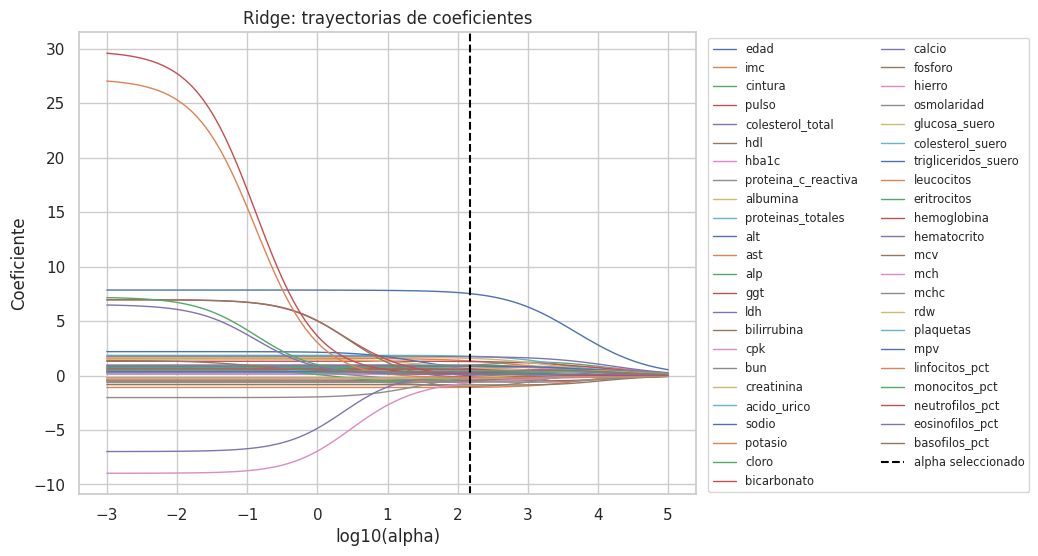

In [20]:
#Trayectoria de coeficientes Ridge
scaler_path = StandardScaler().fit(X_train)
X_train_scaled = scaler_path.transform(X_train)

ridge_coefs = np.asarray([Ridge(alpha=a).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(13, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), ridge_coefs[:, j], lw=1, label=name)
plt.axvline(np.log10(ridge_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Ridge: trayectorias de coeficientes")
plt.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize="x-small", ncol=2)
plt.subplots_adjust(right=0.60)
plt.show()

**Evolución de los coeficientes de Ridge**

Con α pequeño los coeficientes se parecen a OLS; al aumentar α se encogen hacia cero (sin llegar a anularse), y con α muy grande el modelo pierde capacidad predictiva. La línea discontinua marca el α elegido (≈ 148,5). **Ridge no elimina variables**, solo las encoge, a diferencia de Lasso.

###Regresión Lasso

In [21]:
lasso_pipe = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=20000))])
lasso_search = GridSearchCV(lasso_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
lasso_search.fit(X_train, y_train)
print("Lasso: mejor alpha =", lasso_search.best_params_["model__alpha"],
      "| MSE CV =", round(-lasso_search.best_score_, 1))

Lasso: mejor alpha = 0.02848035868435802 | MSE CV = 264.6


Con el mismo procedimiento, Lasso obtiene **α ≈ 0,028** (MSE CV = 264,6). Es una penalización débil: el modelo óptimo apenas elimina variables. No comparamos los α de Ridge y Lasso directamente, porque usan penalizaciones distintas.

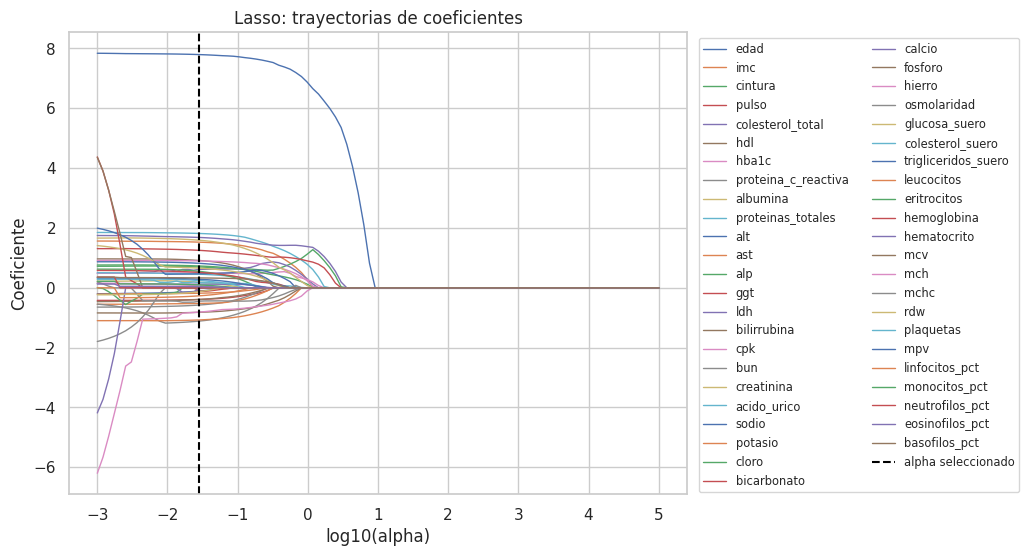

In [22]:
#Trayectoria de coeficientes Lasso
lasso_coefs = np.asarray([Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(13, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), lasso_coefs[:, j], lw=1, label=name)
plt.axvline(np.log10(lasso_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Lasso: trayectorias de coeficientes")
plt.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize="x-small", ncol=2)
plt.subplots_adjust(right=0.60)
plt.show()

**Evolución de los coeficientes de Lasso**

A diferencia de Ridge, al aumentar α algunos coeficientes **llegan a cero** (Lasso elimina variables). El α elegido (≈ 0,028, línea discontinua) está en una zona donde todavía se mantienen la mayoría de los predictores.

In [23]:
#Variables que conserva Lasso
lasso_model = lasso_search.best_estimator_.named_steps["model"]
lasso_coef = pd.Series(lasso_model.coef_, index=X_pen.columns)
keep = lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False)
print("Nº de coeficientes no nulos:", (lasso_coef != 0).sum(), "de", len(lasso_coef))
print()
print(keep.round(3).to_string())

Nº de coeficientes no nulos: 42 de 46

edad                   7.795
proteinas_totales      1.816
ldh                    1.683
creatinina             1.590
imc                    1.526
ggt                    1.252
bun                   -1.112
potasio               -1.073
hdl                    0.913
cpk                    0.898
fosforo               -0.818
trigliceridos_suero    0.818
mch                   -0.812
alp                    0.729
cintura                0.696
glucosa_suero          0.657
colesterol_total       0.616
proteina_c_reactiva   -0.575
cloro                  0.549
ast                   -0.522
bicarbonato            0.515
hba1c                  0.495
sodio                  0.467
acido_urico            0.456
mchc                  -0.446
pulso                 -0.390
bilirrubina           -0.389
basofilos_pct          0.331
mpv                    0.286
linfocitos_pct        -0.268
plaquetas              0.243
albumina               0.188
leucocitos            -0.180
cole

**Interpretación de la selección de variables**

Lasso conserva **42 de los 46 predictores** (elimina solo cuatro), con `edad` como mayor coeficiente (≈ 7,80), seguida de `proteinas_totales`, `ldh`, `creatinina`, `imc` y `ggt`. Elimina `osmolaridad`, `eritrocitos`, `mcv` y `neutrofilos_pct`, muy correlacionadas con otras variables del hemograma/electrolitos.

Los coeficientes corresponden a variables estandarizadas (cambio asociado a una desviación típica). Eliminar una variable no implica que no se relacione con `pas`: su información puede estar ya recogida por otras. En nuestro caso la selección es limitada; el interés de Lasso aquí es más la estabilidad que la reducción de variables.

###Comparación de OLS, Ridge, Lasso y Elastic Net

In [24]:
#Comparación final en test: OLS, Ridge, Lasso y (opcional) Elastic Net
elastic_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(max_iter=10000))]),
    {"model__alpha": np.logspace(-3, 3, 20), "model__l1_ratio": [0.5, 0.9, 0.99, 1.0]},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
elastic_search.fit(X_train, y_train)

models = {
    "OLS": ols_pipe,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "Elastic Net": elastic_search.best_estimator_,
}
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({"Modelo": name,
                    "MSE test": mean_squared_error(y_test, pred),
                    "R² test": r2_score(y_test, pred)})
display(pd.DataFrame(results).sort_values("MSE test").round(3))

,Modelo,MSE test,R² test
2,Lasso,235.623,0.283
3,Elastic Net,235.919,0.282
1,Ridge,236.099,0.282
0,OLS,236.519,0.281


Comparamos OLS, Ridge, Lasso y Elastic Net sobre el mismo test (parámetros elegidos por CV):

- **Lasso:** MSE 235,623, R² 0,283 (el mejor).
- **Elastic Net:** 235,919 / 0,282; **Ridge:** 236,099 / 0,282.
- **OLS:** 236,519 / 0,281 (el peor).

Los tres regularizados mejoran a OLS, pero la diferencia es mínima (menos de 1 punto de MSE y 0,002 de R²): no hay un ganador claro en esta partición de test.

## 5. Análisis mediante PCA

Como los 46 predictores están correlacionados, **PCA** los resume en componentes principales no correlacionadas y ordenadas por varianza explicada. Usamos los mismos 46 predictores estandarizados (9.075 participantes). Es una técnica **no supervisada**: no usamos `pas` para construir las componentes.

In [25]:
# Primero ponemos todas las variables en la misma escala (media 0, desviación 1),
#   para que ninguna "pese" más solo por tener números más grandes.
X_scaled = StandardScaler().fit_transform(X_pen)
pca = PCA()
Z = pca.fit_transform(X_scaled)

loadings = pca.components_          #filas = componentes (direcciones )
var = pca.explained_variance_       #varianza de cada Zj
ratio = pca.explained_variance_ratio_

print("Resumen del modelo PCA (varianza explicada):")
summary_pca = pd.DataFrame({
    "Desv. típica": np.sqrt(var),
    "Varianza": var,
    "Proporción": ratio,
    "Acumulada": np.cumsum(ratio),
}, index=[f"PC{i+1}" for i in range(len(var))])
display(summary_pca.head(10).round(3))

#¿Cuántas componentes hacen falta para alcanzar distintos niveles de varianza?
print()
for thr in [0.7, 0.8, 0.9]:
    k = int(np.searchsorted(np.cumsum(ratio), thr) + 1)
    print(f"  {int(thr*100)}% de varianza -> {k} componentes")

Resumen del modelo PCA (varianza explicada):


,Desv. típica,Varianza,Proporción,Acumulada
PC1,2.227,4.961,0.108,0.108
PC2,2.041,4.168,0.091,0.198
PC3,1.820,3.312,0.072,0.270
PC4,1.605,2.577,0.056,0.326
PC5,1.565,2.450,0.053,0.380
PC6,1.421,2.018,0.044,0.424
PC7,1.412,1.993,0.043,0.467
PC8,1.318,1.737,0.038,0.505
PC9,1.275,1.625,0.035,0.540
PC10,1.243,1.546,0.034,0.574



  70% de varianza -> 15 componentes
  80% de varianza -> 20 componentes
  90% de varianza -> 27 componentes


**Resumen del modelo PCA**

Obtenemos 46 componentes. **PC1 explica el 10,8 %** de la varianza, PC2 el 9,1 % y PC3 el 7,2 %; las dos primeras juntas, el 19,8 %. La varianza está muy repartida: **no podemos reducir a 2–3 componentes sin perder mucha información**.

In [26]:
#Verificación: explained_variance_ == valores singulares^2 / (n-1)
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
print("¿explained_variance_ == S²/(n-1)?", np.allclose(var, S**2 / (len(X_scaled) - 1)))

#Justificación de la desviación típica de la primera componente
print()
print("Desviación típica de PC1:", round(np.sqrt(var[0]), 3))
print("Varianza total (suma autovalores):", round(var.sum(), 2), "= nº de variables:", X_pen.shape[1])

¿explained_variance_ == S²/(n-1)? True

Desviación típica de PC1: 2.227
Varianza total (suma autovalores): 46.01 = nº de variables: 46


**Justificación de la desviación típica de la primera componente**

La desviación típica de PC1 es **2,227**. Al estandarizar las 46 variables, cada una tiene varianza ≈ 1 y la varianza total es ≈ 46. PC1 tiene varianza **4,961** (la mayor), y su desviación típica es $\sigma_{PC1}=\sqrt{4{,}961}\approx 2{,}227$. Por eso PC1 explica el $10{,}8\%$ de la varianza ($4{,}961/46{,}01$). Comprobamos además por SVD que la varianza calculada coincide con los valores singulares al cuadrado entre (n−1).

PC1 concentra más varianza que cualquier variable original por separado, pero sigue siendo una fracción pequeña del total.

**Scree plot y varianza acumulada**

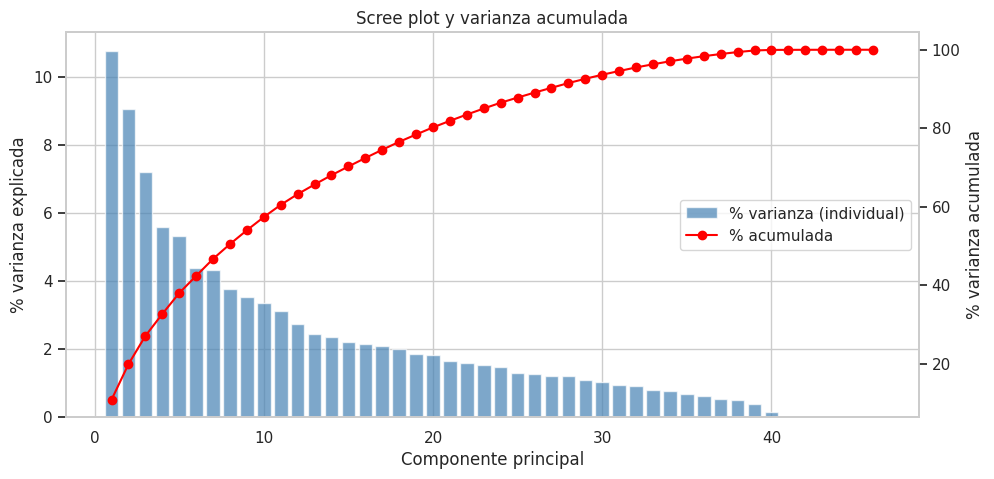

In [27]:
#Scree plot y varianza acumulada
fig, ax1 = plt.subplots(figsize=(11, 5))
comp_idx = np.arange(1, len(var) + 1)
ax1.bar(comp_idx, ratio * 100, color="steelblue", alpha=0.7, label="% varianza (individual)")
ax1.set_xlabel("Componente principal"); ax1.set_ylabel("% varianza explicada")

ax2 = ax1.twinx()
ax2.plot(comp_idx, np.cumsum(ratio) * 100, color="red", marker="o", label="% acumulada")
ax2.set_ylabel("% varianza acumulada")
ax2.grid(False)

l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, loc="center right")
plt.title("Scree plot y varianza acumulada")
plt.show()

El scree plot muestra la varianza por componente (barras) y acumulada (línea roja): la caída es gradual, sin un codo claro, señal de información repartida.

| Varianza a conservar | Componentes |
|---|---|
| 70 % | 15 |
| 80 % | 20 |
| 90 % | 27 |

Las 8 primeras componentes acumulan el 50,5 % y las 10 primeras el 57,4 %. PCA reduce dimensiones, pero de forma moderada; a cambio, ayuda a ver qué grupos de variables se mueven juntos.

In [28]:
loadings_df = pd.DataFrame(loadings.T, index=X_pen.columns,
                           columns=[f"PC{i+1}" for i in range(X_pen.shape[1])])
for pc in ["PC1", "PC2", "PC3"]:
    top = loadings_df[pc].reindex(loadings_df[pc].abs().sort_values(ascending=False).index).head(6)
    print(f"{pc}  variables con mayor |peso|:")
    print(top.round(3).to_string())
    print()

PC1  variables con mayor |peso|:
hemoglobina    0.383
hematocrito    0.351
mch            0.287
rdw           -0.277
mchc           0.274
hierro         0.269

PC2  variables con mayor |peso|:
cintura                0.358
imc                    0.316
proteina_c_reactiva    0.265
hba1c                  0.262
trigliceridos_suero    0.252
ggt                    0.248

PC3  variables con mayor |peso|:
osmolaridad    0.359
edad           0.293
bun            0.287
sodio          0.262
mcv            0.257
eritrocitos   -0.254



**Interpretación de las componentes principales** (cargas o *loadings*):

- **PC1:** domina el hemograma — `hemoglobina` (0,383), `hematocrito` (0,351), `mch`, `rdw` (−0,277), `mchc` e `hierro`.
- **PC2:** adiposidad/salud metabólica — `cintura` (0,358), `imc` (0,316), `proteina_c_reactiva`, `hba1c`, `trigliceridos_suero` y `ggt`.
- **PC3:** equilibrio de líquidos/electrolitos y función renal — `osmolaridad` (0,359), `edad`, `bun`, `sodio`, `mcv` y `eritrocitos` (−0,254).

Las componentes son combinaciones matemáticas, no variables clínicas, y su signo es arbitrario.

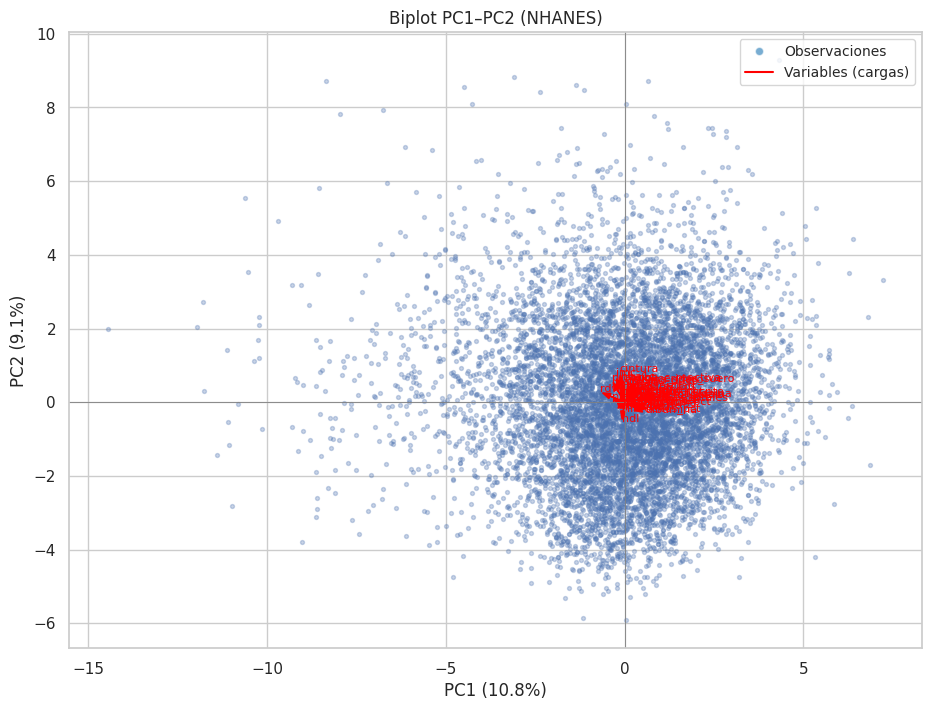

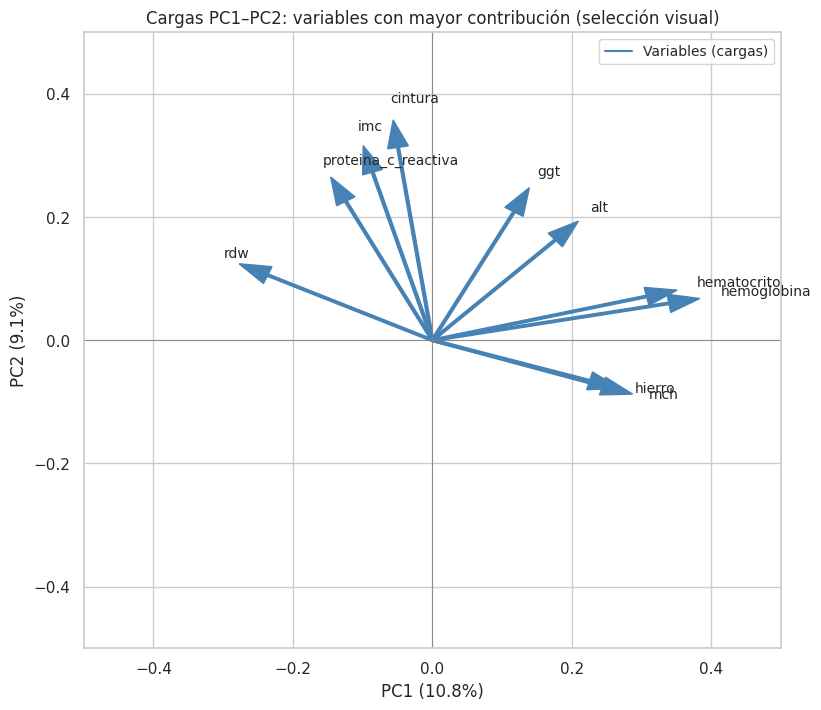

In [29]:
#Biplot PC1-PC2
comp = pca.components_.T * np.sqrt(pca.explained_variance_)
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(Z[:, 0], Z[:, 1], s=8, alpha=0.3)
for j, name in enumerate(X_pen.columns):
    ax.arrow(0, 0, comp[j, 0], comp[j, 1], color="red", width=0.002,
             head_width=0.15, length_includes_head=True)
    ax.text(comp[j, 0] * 1.12, comp[j, 1] * 1.12, name, color="red", fontsize=8)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Biplot PC1–PC2 (NHANES)")

#Leyenda: qué representa cada elemento del biplot
biplot_legend = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#1f77b4",
           markersize=6, alpha=0.6, label="Observaciones"),
    Line2D([0], [0], color="red", lw=1.5, label="Variables (cargas)"),
]
ax.legend(handles=biplot_legend, fontsize="small", loc="upper right")
plt.show()

#Lectura alternativa: solo las variables con mayor contribución a PC1–PC2
#(selección visual de las aproximadamente 10 con mayor norma de cargas en el plano PC1–PC2).
contrib = np.sqrt(loadings[0, :] ** 2 + loadings[1, :] ** 2)
top_idx = np.argsort(contrib)[::-1][:10]

fig, ax = plt.subplots(figsize=(9, 8))
for j in top_idx:
    x = loadings[0, j]
    y = loadings[1, j]
    ax.arrow(0, 0, x, y, color="steelblue", width=0.004,
             head_width=0.03, length_includes_head=True)
    ax.text(x * 1.08, y * 1.08, X_pen.columns[j], fontsize=10)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlim(-0.5, 0.5); ax.set_ylim(-0.5, 0.5)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Cargas PC1–PC2: variables con mayor contribución (selección visual)")
ax.legend(handles=[Line2D([0], [0], color="steelblue", lw=1.5,
                          label="Variables (cargas)")], fontsize="small", loc="upper right")
plt.show()

**Interpretación del biplot**

Los puntos son los participantes y las flechas las variables. Flechas en la misma dirección indican correlación positiva; en sentidos opuestos, negativa; su longitud refleja su peso en el plano. Como hay 46 variables, añadimos un segundo gráfico con las 10 de mayor contribución.

Refuerza lo anterior: **PC1** (horizontal) está dominada por el hemograma (`hemoglobina`, `hematocrito`) y **PC2** (vertical) por la adiposidad (`cintura`, `imc`) y el metabolismo. Limitación: PC1+PC2 solo explican el 19,8 % de la varianza, así que el biplot muestra relaciones interesantes pero no toda la información.

### Extensión (opcional): PCR y PLS

Podemos usar las componentes para predecir `pas`:

- **PCR:** aplica PCA a los predictores (sin mirar `pas`) y luego regresión.
- **PLS:** construye componentes teniendo en cuenta `pas`.

Elegimos el número de componentes por validación cruzada de 10 particiones (PCR: 1–46; PLS: 1–20), con los mismos datos de entrenamiento.

In [30]:
pcr_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("model", LinearRegression())]),
    {"pca__n_components": range(1, X_pen.shape[1] + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pcr_search.fit(X_train, y_train)

n_pls = 20
pls_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pls", PLSRegression(scale=False))]),
    {"pls__n_components": range(1, n_pls + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pls_search.fit(X_train, y_train)

print("PCR: m =", pcr_search.best_params_["pca__n_components"], "| MSE CV =", round(-pcr_search.best_score_, 1))
print("PLS: m =", pls_search.best_params_["pls__n_components"], "| MSE CV =", round(-pls_search.best_score_, 1))

PCR: m = 40 | MSE CV = 264.6
PLS: m = 16 | MSE CV = 264.6


**Resultados de PCR y PLS**

- **PCR:** 40 componentes, MSE CV ≈ 264,6.
- **PLS:** 16 componentes, MSE CV ≈ 264,6.

Ambos alcanzan prácticamente el mismo error, pero **PLS necesita muchas menos componentes** (16 frente a 40): las componentes que más varianza explican no son necesariamente las más útiles para predecir.

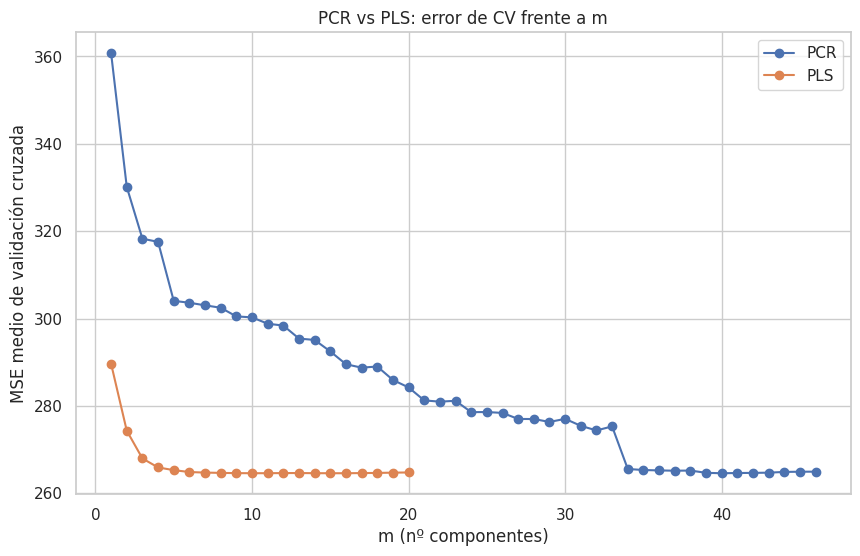

In [31]:
mses_pcr = -pcr_search.cv_results_["mean_test_score"]
mses_pls = -pls_search.cv_results_["mean_test_score"]

plt.plot(range(1, X_pen.shape[1] + 1), mses_pcr, marker="o", label="PCR")
plt.plot(range(1, n_pls + 1), mses_pls, marker="o", label="PLS")
plt.xlabel("m (nº componentes)"); plt.ylabel("MSE medio de validación cruzada")
plt.title("PCR vs PLS: error de CV frente a m")
plt.legend()
plt.show()

**Comparación gráfica de PCR y PLS**

La curva de PCR desciende lentamente hasta su mínimo con 40 componentes; PLS alcanza su mínimo ya con 16. Se aprecia la diferencia entre **resumir información** (PCA/PCR) y **resumir información útil para predecir** (PLS). Para estos datos, PLS es más eficiente en número de componentes.

## 6. Regresión logística

Planteamos ahora un problema de **clasificación binaria**: predecir si una persona tiene hipertensión diagnosticada (`hipertension`), con valores `si`/`no`. El modelo estima una probabilidad entre 0 y 1 y, por defecto, clasificamos como `si` si supera el umbral 0,5.

Ojo: predecimos un **diagnóstico registrado**, no diagnosticamos médicamente a nadie.

In [32]:
df["hipertension"].value_counts(dropna=False)

hipertension
no     6719
si     4005
NaN      15
Name: count, dtype: int64

Hay **6.719 personas sin hipertensión y 4.005 con diagnóstico** (15 sin información). Existe cierto desequilibrio, pero no extremo; lo tendremos en cuenta al estratificar la partición entrenamiento/test.

In [33]:
#Predictores: edad, IMC, sexo, colesterol total, HDL y tabaco
cols_log = ["hipertension", "edad", "imc", "sexo", "colesterol_total", "hdl", "tabaco"]
d_log = df[cols_log].dropna()
d_log = d_log[d_log["hipertension"].isin(["si", "no"])].copy()
d_log["y"] = (d_log["hipertension"] == "si").astype(int)
d_log = pd.get_dummies(
    d_log,
    columns=["sexo", "tabaco"],
    dtype=int,
)
d_log = d_log.drop(columns=["sexo_mujer", "tabaco_fumador"])
feats = [c for c in d_log.columns if c not in ("hipertension", "y")]
X_log = d_log[feats]
y_log = d_log["y"]

print("Observaciones:", d_log.shape[0], "| Prevalencia de hipertensión:", round(y_log.mean(), 3))

Observaciones: 9938 | Prevalencia de hipertensión: 0.372


Seleccionamos como predictores `edad`, `imc`, `sexo`, `colesterol_total`, `hdl` y `tabaco`. Convertimos `hipertension` en `y` (1 = sí, 0 = no) y las cualitativas en binarias con `get_dummies()`. Tras eliminar ausentes quedan **9.938 participantes** (37,2 % con hipertensión). Este porcentaje no es una prevalencia poblacional: para eso harían falta los pesos muestrales de NHANES.

### 6.2 Ajuste e interpretación (odds ratios)

 Este modelo se ajusta con **todos los datos** (n = 9.938) para **interpretar asociaciones**; la capacidad predictiva se evalúa en 6.3 con una partición entrenamiento/test.

In [34]:
#statsmodels para interpretación (coeficientes y odds ratios)
# Ajustamos un modelo que da, para cada persona, una probabilidad de tener
#   hipertensión. Luego convertimos los coeficientes a "odds ratios" (OR) para
#   leerlos de forma intuitiva (OR > 1 = aumenta, OR < 1 = disminuye, OR = 1 = nada).
X_log_const = sm.add_constant(X_log)
logit = sm.Logit(y_log, X_log_const).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 9938
Model:                          Logit   Df Residuals:                     9930
Method:                           MLE   Df Model:                            7
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                  0.1893
Time:                        01:55:35   Log-Likelihood:                -5317.9
converged:                       True   LL-Null:                       -6559.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -5.1269      0.218    -23.485      0.000      -5.555      -4.699
edad                 0.0628      0.002     39.297      0.000       0.060       0.066
imc                  0.0716 

In [35]:
odds = np.exp(logit.params)
print("Odds ratios (exp(β)):")
print(odds.round(3).to_string())

Odds ratios (exp(β)):
const               0.006
edad                1.065
imc                 1.074
colesterol_total    0.998
hdl                 0.998
sexo_hombre         1.008
tabaco_exfumador    0.723
tabaco_nunca        0.659


**Interpretación de la regresión logística**

Como los coeficientes de un modelo logístico no son directamente cambios en la probabilidad, los convertimos en **odds ratios** (OR = e^coef). La *odds* es el cociente "probabilidad de sí / probabilidad de no"; el OR compara las odds al cambiar una variable: **OR = 1** (sin cambio), **OR > 1** (aumenta), **OR < 1** (disminuye). Un OR de 1,07 no significa "7 puntos porcentuales más", sino que las odds se multiplican por 1,07.

Resultados:

- **`edad` (OR = 1,065):** por cada año, las odds de hipertensión se multiplican por 1,065 (+6,5 %; ≈ +87 % por década). Es la asociación más clara.
- **`imc` (OR = 1,074):** +7,4 % por unidad de IMC.
- **`colesterol_total` (OR = 0,998):** asociación negativa muy pequeña, aunque significativa.
- **`hdl` (OR = 0,998, p = 0,167):** sin evidencia de asociación.
- **`sexo_hombre` (OR = 1,008, p = 0,882):** sin diferencias por sexo.
- **`tabaco`:** frente a los fumadores, los exfumadores tienen odds un 27,7 % menores (OR = 0,723) y los que nunca fumaron un 34,1 % menores (OR = 0,659); ambas significativas.

Edad e IMC se asocian positivamente con la hipertensión, y no fumar con odds menores. Son asociaciones observacionales, no causales.

### 6.3 Evaluación: matriz de confusión y medidas

In [36]:
# Entrenamos en el 80 % y evaluamos en el 20 % (estratificado: mantiene la
#   proporción de hipertensos en ambos lados).
X_tr, X_te, y_tr, y_te = train_test_split(
    X_log, y_log, test_size=0.2, random_state=RANDOM_STATE, stratify=y_log)

sc_log = StandardScaler().fit(X_tr)
lr = LogisticRegression(max_iter=1000).fit(sc_log.transform(X_tr), y_tr)

pred = lr.predict(sc_log.transform(X_te))
proba = lr.predict_proba(sc_log.transform(X_te))[:, 1]

cm = confusion_matrix(y_te, pred)
print("Matriz de confusión (filas = real, columnas = predicha):")
print(cm)
print()
print(f"Accuracy : {accuracy_score(y_te, pred):.3f}")
print(f"Precision: {precision_score(y_te, pred):.3f}")
print(f"Recall   : {recall_score(y_te, pred):.3f}")
print(f"F1-score : {f1_score(y_te, pred):.3f}")
print(f"AUC      : {roc_auc_score(y_te, proba):.3f}")

Matriz de confusión (filas = real, columnas = predicha):
[[1045  203]
 [ 321  419]]

Accuracy : 0.736
Precision: 0.674
Recall   : 0.566
F1-score : 0.615
AUC      : 0.803


**Evaluación del modelo de regresión logística**

Entrenamos con el 80 % y evaluamos sobre el 20 % restante (partición estratificada). Matriz de confusión (filas = real, columnas = predicha):

- **1.045** verdaderos negativos y **419** verdaderos positivos.
- **203** falsos positivos y **321** falsos negativos.

Métricas: **accuracy 0,736**, **precision 0,674**, **recall 0,566**, **F1 0,615**, **AUC 0,803**.

El modelo identifica mejor a los sanos que a los hipertensos: deja sin detectar el 43,4 % de los casos positivos. Aunque el accuracy y el AUC son aceptables, **el recall de la clase positiva es la principal limitación** — y muestra por qué no basta el porcentaje global de aciertos.

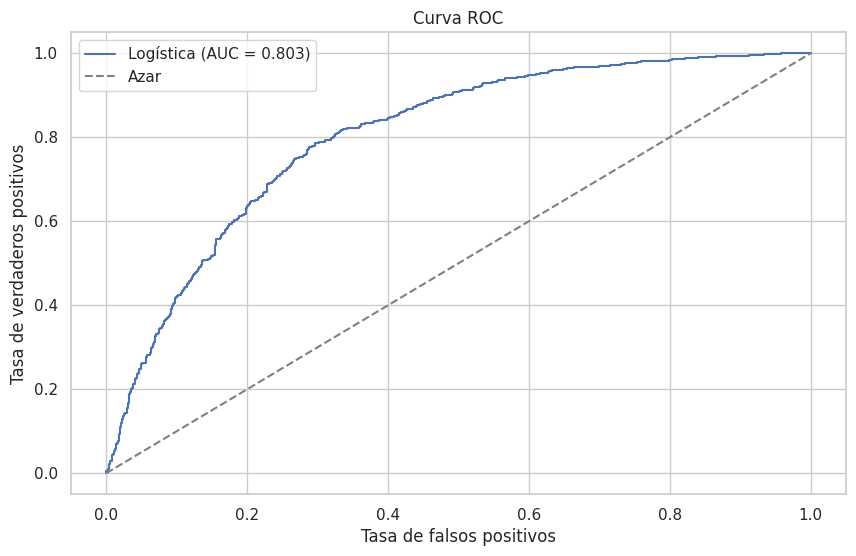

In [37]:
fpr, tpr, _ = roc_curve(y_te, proba)
plt.plot(fpr, tpr, label=f"Logística (AUC = {roc_auc_score(y_te, proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Azar")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC")
plt.legend()
plt.show()

**Interpretación de la curva ROC**

La curva ROC enfrenta la tasa de verdaderos positivos (recall) a la de falsos positivos al variar el umbral; la diagonal es el azar. El **AUC = 0,803** indica buena capacidad para ordenar a los participantes por su probabilidad de hipertensión.

El AUC no depende del umbral, pero el recall sí: con umbral 0,5 es solo 0,566. Un umbral más bajo detectaría más hipertensos a costa de más falsos positivos, lo que se evalúa en la celda siguiente.

In [38]:
#Efecto del umbral de decisión sobre recall y especificidad
#Con umbral 0.5 se escapan bastantes hipertensos; bajarlo detecta más casos
#a costa de más falsos positivos. Solo es ilustrativo: el umbral no se elige
#mirando el test.
filas = []
for t in [0.3, 0.4, 0.5, 0.6]:
    pred_t = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred_t).ravel()
    filas.append({"Umbral": t,
                  "Accuracy": accuracy_score(y_te, pred_t),
                  "Recall": tp / (tp + fn),
                  "Especificidad": tn / (tn + fp)})
display(pd.DataFrame(filas).round(3))

,Umbral,Accuracy,Recall,Especificidad
0,0.3,0.697,0.839,0.613
1,0.4,0.737,0.719,0.748
2,0.5,0.736,0.566,0.837
3,0.6,0.711,0.377,0.909


**Elección del umbral:** el umbral 0.5 es una convención, no una obligación. Bajarlo aumenta el **recall** (se detectan más hipertensos) pero reduce la **especificidad** (más falsas alarmas); subirlo hace lo contrario. Por ejemplo, con umbral 0.4 la accuracy se mantiene (≈ 0.74) pero el recall sube de ≈ 0.57 a ≈ 0.72, mientras la especificidad baja de ≈ 0.84 a ≈ 0.75. En un contexto de cribado clínico, donde dejar sin detectar a un hipertenso es más costoso que una falsa alarma, sería razonable usar un umbral más bajo. Para fijarlo de forma rigurosa habría que elegirlo con validación cruzada sobre el entrenamiento, no sobre el test; la tabla anterior solo ilustra el compromiso. El **AUC** no depende del umbral.

###6.4 (Opcional) Comparación con LDA

In [39]:
lda = LinearDiscriminantAnalysis().fit(sc_log.transform(X_tr), y_tr)
pred_lda = lda.predict(sc_log.transform(X_te))
proba_lda = lda.predict_proba(sc_log.transform(X_te))[:, 1]

print("LDA:")
print(f"  Accuracy: {accuracy_score(y_te, pred_lda):.3f}")
print(f"  AUC     : {roc_auc_score(y_te, proba_lda):.3f}")

LDA:
  Accuracy: 0.737
  AUC     : 0.803


**LDA (Análisis Discriminante Lineal)** obtiene accuracy 0,737 y AUC 0,803, prácticamente idénticos a la regresión logística (0,736 / 0,803). No hay mejora relevante; preferimos la logística por la interpretabilidad de sus odds ratios.

## 7. ¿Una o varias bases de datos?

Usamos **una única base de datos (NHANES)**, suficiente para todas las técnicas: regresión (`pas`), Ridge/Lasso y PCA (46 biomarcadores) y regresión logística (`hipertension`). Cada apartado selecciona sus columnas y elimina los ausentes correspondientes, por lo que el número de participantes varía. Para evaluar, separamos entrenamiento/test y usamos validación cruzada (sobre el entrenamiento) para elegir α y el número de componentes.

## 8. Conclusiones

- **Relaciones encontradas:** la **edad** es el principal factor asociado a la presión sistólica (+0,49 mmHg/año) y el **IMC** también se asocia a mayor presión (+0,39 mmHg/unidad). En la hipertensión, `edad` y `imc` son los predictores con mayor asociación (OR ≈ 1,07). Son asociaciones observacionales, no causales.
- **Variables más relevantes:** `edad` y `imc` aparecen de forma consistente en regresión, Lasso y logística. Los demás biomarcadores añaden poca capacidad predictiva; de hecho, **Lasso conserva 42 de 46 variables**, así que su selección es limitada y no demuestra que el resto carezca de efecto (pueden estar correlacionados con `edad`/`imc` o entre sí).
- **Diferencias entre modelos:** la diferencia de MSE test entre OLS (≈ 236,5) y Ridge/Lasso (≈ 235,6–236,1) es pequeña y está dentro del ruido de una partición de test; el valor de la regularización aquí es sobre todo **estabilidad** ante la colinealidad. PLS alcanza a PCR con muchas menos componentes (16 frente a 40).
- **Qué aporta PCA:** resume los 46 biomarcadores, pero la reducción es moderada (8 componentes → 50,5 %; 15 → 70 %; 20 → 80 %; 27 → 90 %). PC1 refleja el hemograma y PC2 la adiposidad/síndrome metabólico, mostrando qué grupos de variables se mueven juntos.
- **Limitaciones:** no se usan los pesos muestrales (`peso_examen`), se trabaja con casos completos (sin imputar) y se excluye la submuestra en ayunas; la medicación puede atenuar algunas asociaciones; `edad` está truncada en 80.

**Conclusión:** la **edad** y el **IMC** son lo que mejor explica la presión arterial y el riesgo de hipertensión; el resto de medidas añade poco, y las técnicas avanzadas (Ridge, Lasso, PCA) confirman más que revolucionan los resultados — su valor es aportar **estabilidad** e **interpretación**.